# Random Forest on Dataset2 (Portugese Class)
$\textit{by Shivam Shilpkar(MS24238)}$

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

df=pd.read_csv('student-por.csv', sep=';')
df.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


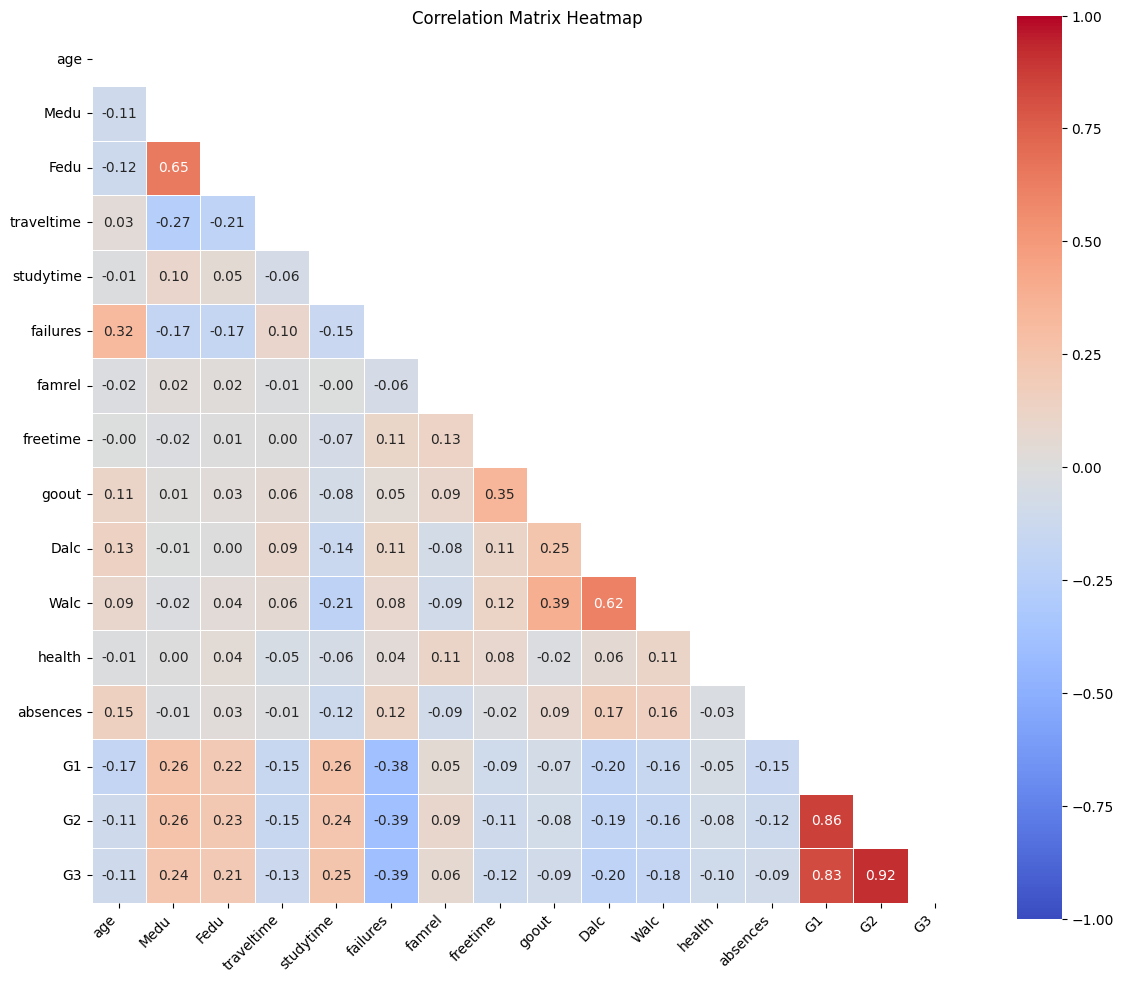

In [3]:
plt.figure(figsize=(12, 10))
corr_matrix = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",  # Good divergent color palette for negative (-1) to positive (+1) rules
    vmin=-1,
    vmax=1,  # Forces the color boundaries to represent true correlation limits
    center=0,  # Centers the neutral color at 0 (no correlation)
    square=True,  # Forces the grid cells to be perfectly square
    linewidths=0.5,  # Adds clean dividers between squares
)
plt.title("Correlation Matrix Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
# Select the input variables and target variable

feature_names = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'goout', 'G1', 'G2']
y = df["G3"].to_numpy()

X = []
for name in feature_names:
    X.append(df[name].to_numpy())
X = np.array(X).T
print(np.shape(X))

(649, 9)


In [5]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=56
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 519
Testing samples: 130


In [6]:


regressor = RandomForestRegressor(
    n_estimators=100,
    random_state=56
)

regressor.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [7]:
predictions = regressor.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)
n = len(y_test)
p = len(X[0])
adj_r2 = 1-((1-r2)*(n-1)/(n-p-1))

print(f'MAE = {mae:.4f}')
print(f'RMSE = {rmse:.4f}')
print(f'R^2 = {r2:.4f}')
print(f'Adjusted R^2 = {adj_r2:.4f}')

MAE = 0.9881
RMSE = 1.5705
R^2 = 0.8315
Adjusted R^2 = 0.8189


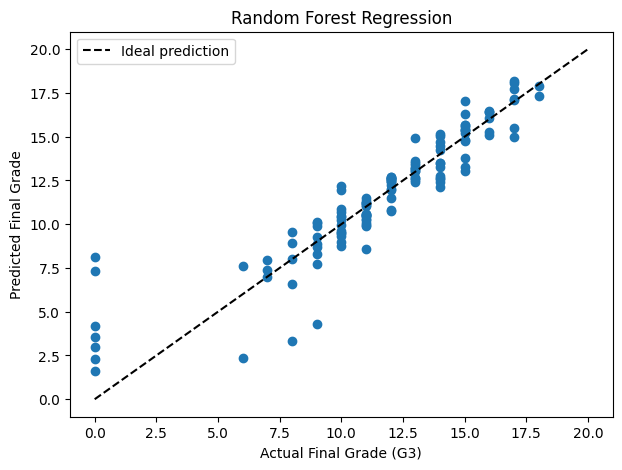

In [8]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions)

plt.plot(
    [0, 20],
    [0, 20],
    color='black',
    linestyle='--',
    label='Ideal prediction'
)

plt.xlabel('Actual Final Grade (G3)')
plt.ylabel('Predicted Final Grade')
plt.title('Random Forest Regression')
plt.legend()
plt.show()

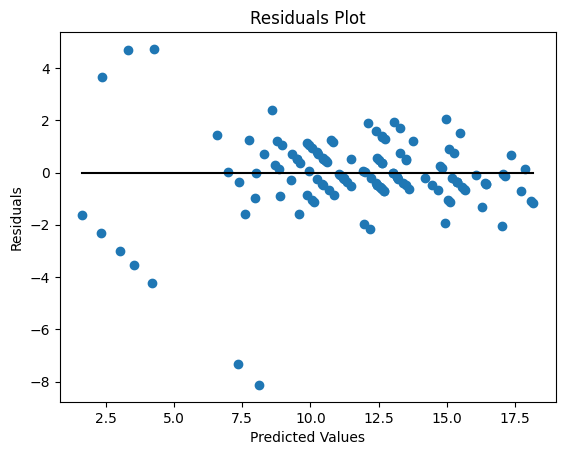

In [9]:
# Plotting residuals in order to check for any bias in the errors

residuals = y_test - predictions
plt.scatter(predictions, residuals)
plt.plot([min(predictions), max(predictions)], [0, 0], color='black')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals Plot')
plt.show()


      Feature  Importance
8          G2    0.833440
1        Medu    0.033659
7          G1    0.027550
0         age    0.025715
3  traveltime    0.020805
6       goout    0.020637
5    failures    0.015271
2        Fedu    0.013497
4   studytime    0.009426


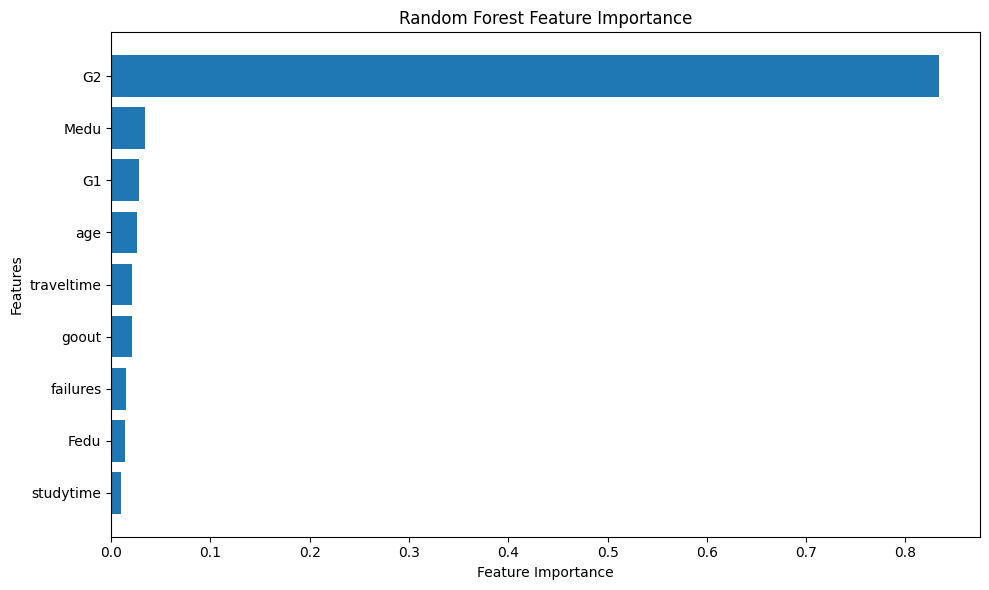

In [10]:
# Feature Importance using Random Forest

importances = regressor.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display feature importance
print(importance_df)

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Random Forest Feature Importance')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()